In [71]:
# ===============================
# import libraries
# ===============================
import numpy as np
import pandas as pd
from pathlib import Path
import chartgazing as cg

cg.set_size("square")

In [72]:
# ===============================
# import card data
# ===============================

# set data directory
DATA_DIR = Path("data/sets")

# combine every saved set
pokemon_all = pd.concat(
    [pd.read_csv(path, dtype={"number": str, "product_id": str, "variant": str}, parse_dates=["date"]) for path in DATA_DIR.glob("*.csv")],
    ignore_index=True
)

# additional data on each set
sets_df = pd.read_csv("data/sets_info.csv", parse_dates=["release_date"])
pokemon_all = pokemon_all.merge(sets_df, on="set_slug", how="left")

In [73]:
# ===============================
# clean data
# ===============================
pokemon_all["variant"] = pokemon_all["variant"].fillna("Standard")
pokemon_all["price"] = pokemon_all["price"].replace(0, np.nan)
pokemon_all["date"] = pokemon_all["date"].dt.to_period("M").dt.to_timestamp()
pokemon_all["decade"] = (pokemon_all["release_date"].dt.year // 10) * 10


for col in ["grade", "set_slug", "set_name", "language", "name", "variant"]:
    pokemon_all[col] = pokemon_all[col].astype("category")

In [74]:
# ===============================
# Changes for all cards
# ===============================
GRADE = "Ungraded"
IMAGE_DIR = "images/4x5"
source = "Source: PriceCharting.com"

all_prices = pokemon_all.dropna(subset=["price"])

# TEMP LINE
# priced_cards = all_prices[all_prices["grade"] == GRADE]
priced_cards = all_prices

latest_date = priced_cards["date"].max()
latest_cards = priced_cards[priced_cards["date"] == latest_date]

def fmt(value):
    return f"${value:,.0f}" if value >= 1000 else f"${value:.2f}"

def short_set(set_name):
    return set_name.removeprefix("Pokemon ")

def one_per_card(cards):
    return(
        cards.assign(not_standard=cards["variant"] != "Standard")
        .sort_values(["not_standard", "price"])
        .drop_duplicates(["set_slug", "number", "name"])
    )

In [75]:
# ===============================
# prepare 2026 card price change
# ===============================
cards_2026 = all_prices.assign(date=all_prices["date"] - pd.DateOffset(months=1))
cards_2026 = cards_2026[
    (cards_2026["date"] >= "2026-01-01")
    & (cards_2026["grade"] == GRADE)
]

year_start = cards_2026[cards_2026["date"] == "2026-01-01"].set_index("product_id")["price"]




cards_2026 = cards_2026[cards_2026["product_id"].isin(year_start.index)]

cards_2026["pct_chng"] = (cards_2026["price"] / cards_2026["product_id"].map(year_start) -1) * 100

cards_2026.sort_values(["product_id", "date"])

cards_26 = cards_2026.groupby("date", as_index=False).agg(
    unique_cards = ("product_id", "nunique"),
    PK_pct_chng = ("pct_chng", "median")
)


# ===============================
# import S&P 500 data
# ===============================
sp_500 = pd.read_csv(f"data/S&P_500.csv")

sp_500["Date"] = pd.to_datetime(sp_500["Date"], format="%d/%m/%Y")

sp_500["Change"] = sp_500["Change %"].str.removesuffix("%") 
sp_500 = sp_500[["Date", "Price", "Change"]]

sp_500["Change"] = sp_500["Change"].astype(float)
sp_500["Price"] = sp_500["Price"].str.replace(r"[^\d\.]", "",regex=True).astype(float)

sp_500 = sp_500[sp_500["Date"] >= "2026-01-01"]

sp_500 = sp_500.sort_values(by="Date", ascending=True)

sp_500["SP_pct_chng"] = ((sp_500["Price"] - sp_500["Price"].iloc[0]) / sp_500["Price"].iloc[0]) * 100

sp_500.columns = sp_500.columns.str.lower()


# ===============================
# combined 2026 returns
# ===============================

returns = pd.merge(cards_26, sp_500, on='date')

returns = returns[["date", "PK_pct_chng", "sp_pct_chng"]]

returns = returns.rename(columns={"PK_pct_chng": "Pokémon", "sp_pct_chng": "S&P 500"})

returns = pd.melt(returns, id_vars="date", var_name="category", value_name="pct_change")

returns

,date,category,pct_change
0,2026-01-01,Pokémon,0.000000
1,2026-02-01,Pokémon,2.882537
2,2026-03-01,Pokémon,8.517699
3,2026-04-01,Pokémon,14.285714
4,2026-05-01,Pokémon,19.256491
5,2026-06-01,Pokémon,20.735786
6,2026-07-01,Pokémon,18.107876
7,2026-08-01,Pokémon,26.710695
8,2026-09-01,Pokémon,29.787234
9,2026-01-01,S&P 500,0.000000


In [76]:
# ===============================
# spot-check 1 Oct prices against PriceCharting
# ===============================
from urllib.parse import quote_plus

oct_cards = all_prices[(all_prices["date"] == "2026-01-01") & (all_prices["grade"] == GRADE)].copy()

# spread the sample across price levels so cheap cards that never move don't dominate
oct_cards["tier"] = pd.qcut(oct_cards["price"], 3, labels=["low", "mid", "high"])

sample = oct_cards.groupby("tier", observed=True).sample(n=3, random_state=None)

sample["search"] = (
    "https://www.pricecharting.com/search-products?type=prices&q="
    + (sample["set_name"].astype(str) + " " + sample["name"].astype(str) + " " + sample["number"]).map(quote_plus)
)

sample[["tier", "set_name", "name", "number", "variant", "product_id", "price", "search"]]


,tier,set_name,name,number,variant,product_id,price,search
782116,low,Pokemon Ascended Heroes,pecharunt,143,Ball,11816074,0.50,https://www.pricecharting.com/search-products?...
8839264,low,Pokemon Prismatic Evolutions,earthen vessel,106,Poke Ball,8321673,0.60,https://www.pricecharting.com/search-products?...
11831065,low,Pokemon Team Up,return label,153,Reverse Holo,963133,0.41,https://www.pricecharting.com/search-products?...
3484028,mid,Pokemon Diamond & Pearl,combee,79,Standard,763115,1.00,https://www.pricecharting.com/search-products?...
93625,mid,Pokemon 1999 Topps TV,nidoran,32,Standard,3561049,1.73,https://www.pricecharting.com/search-products?...
5887554,mid,Pokemon Hidden Fates,misty's determination,62,Reverse Holo,964236,2.73,https://www.pricecharting.com/search-products?...
1083031,high,Pokemon Base Set,imposter professor oak,73,1st Edition,715662,41.06,https://www.pricecharting.com/search-products?...
4087840,high,Pokemon Evolutions,zapdos,42,Standard,960330,4.97,https://www.pricecharting.com/search-products?...
1130829,high,Pokemon Battle Styles,rapid strike urshifu vmax,170,Standard,1673350,70.00,https://www.pricecharting.com/search-products?...


In [77]:
pokemon_all.info()

<class 'pandas.DataFrame'>
RangeIndex: 13124130 entries, 0 to 13124129
Data columns (total 13 columns):
 #   Column        Dtype         
---  ------        -----         
 0   grade         category      
 1   date          datetime64[us]
 2   price         float64       
 3   set_slug      category      
 4   product_id    str           
 5   name          category      
 6   variant       category      
 7   number        str           
 8   set_name      category      
 9   language      category      
 10  release_date  datetime64[us]
 11  promo         bool          
 12  decade        int32         
dtypes: bool(1), category(6), datetime64[us](2), float64(1), int32(1), str(2)
memory usage: 797.3 MB


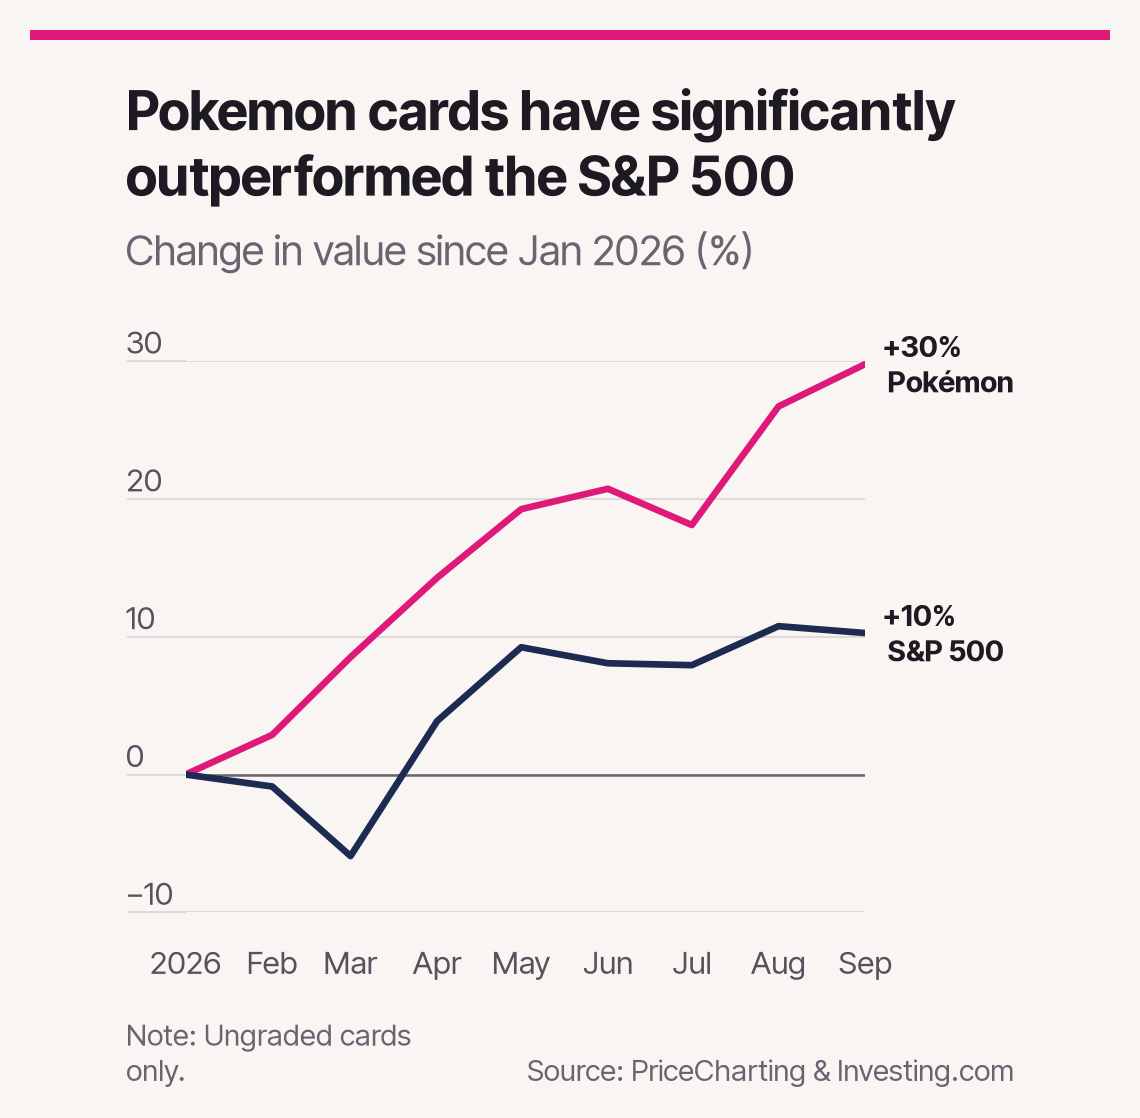

In [80]:
CHART_DIR = Path("charts/")

fig, ax = cg.line(returns, x="date", y="pct_change", group="category",
                  title="Pokemon cards have significantly outperformed the S&P 500",
                  subtitle="Change in value since Jan 2026 (%)",
                  source="Source: PriceCharting & Investing.com",
                  note="Note: Ungraded cards only.",
                  labels=False)

ax.set_yticks([-10, 0, 10, 20, 30, 40, 50])

last = returns.sort_values("date").groupby("category").last()

cg.label_ends(ax, last["pct_change"].to_dict(), fmt=lambda name, value: f"{value:+.0f}% \n {name}")

cg.save(fig, CHART_DIR / "SP500.png")
